# Brent and WTI forecasting with MS-AR and MS-ARX (common evaluation design)

Two-state Markov-switching autoregressions of daily futures log returns, forecasting the cumulative return
1, 5, 10, 20, 30, 40, 50 and 60 trading days ahead. Forecasts are converted to prices.

| Model | Specification |
|---|---|
| MS-AR | $r_t=\mu_{S_t}+\phi\,(r_{t-1}-\mu_{S_{t-1}})+\sigma_{S_t}\varepsilon_t$, two states (calm / turbulent), switching mean and variance, shared AR(1) |
| MS-ARX | the same, plus three lagged inputs $x_{t-1}$ with shared coefficients: the other oil's 1-day return, the dollar index 1-day return, the Brent–WTI spread |

**Common design.** The data, rolling window, re-estimation schedule, horizons, benchmarks, metrics and trading
rule are the same as in the XGBoost notebook (`xgb_1030.ipynb`), so the results can be compared directly.

| Setting | Value |
|---|---|
| Data | `Data/raw/yahoo_daily.csv`, Brent and WTI front-month futures, days on which both trade |
| Rolling window | 1,260 trading days (about 5 years), re-estimated every 21 trading days |
| Out-of-sample origins | 2016-01-01 to 2026-09-30; live test from 2026-10-01 |
| Benchmarks | no change (RW), historical mean, AR(1) |
| Point forecast | $0.5\times$ model mean (equal-weight combination with no change, as in XGBoost); the unshrunk model is reported as `_raw` |

Settings are fixed in advance. There is no tuning on the evaluation period; the earlier validation grid
(`msar.ipynb`) is not used here because 2022–2023 lies inside the out-of-sample period.

**Run.** `pip install statsmodels`, open from `OilForecastQF`, run all cells (about 10–20 minutes).
Results go to `Outputs/msar_common/`.

In [1]:
from dataclasses import dataclass, replace
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.tsa.regime_switching.markov_autoregression import MarkovAutoregression
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
PROJECT_ROOT = next((p.resolve() for p in (Path.cwd(), Path.cwd() / "OilForecastQF", Path.cwd().parent)
                     if (p / "Data" / "raw" / "yahoo_daily.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the notebook from OilForecastQF (needs Data/raw/yahoo_daily.csv).")
pd.set_option("display.width", 180)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#E6E8EB", "font.size": 10})

/Users/heiheidaaaaaa/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/heiheidaaaaaa/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Settings

In [2]:
@dataclass
class Config:
    data_dir: Path = PROJECT_ROOT / "Data" / "raw"
    output_dir: Path = PROJECT_ROOT / "Outputs" / "msar_common"
    targets: tuple = ("brent_fut", "wti_fut")
    horizons: tuple = (1, 5, 10, 20, 30, 40, 50, 60)
    oos_start: str = "2016-01-01"      # first out-of-sample forecast origin
    test_start: str = "2026-10-01"     # live test period
    window: int = 1260                 # rolling estimation window (trading days)
    refit_every: int = 21              # re-estimate every 21 trading days
    ffill_limit: int = 3
    shrink: float = 0.5                # point forecast = 0.5 x model mean
    n_sim: int = 2000                  # simulated paths per origin for the prediction intervals
    seed: int = 5210
    # trading rule (identical to the XGBoost notebook)
    cost_bps: float = 5.0
    trade_hs: tuple = (5, 10, 20)
    main_trade_h: int = 20
    noise_k: float = 0.1
    target_vol: float = 25.0
    max_leverage: float = 2.0
    compare_vol: float = 10.0


cfg = Config()
NAMES = {"brent_fut": "Brent", "wti_fut": "WTI"}
MODELS = ("MSAR", "MSARX")
cfg.output_dir.mkdir(parents=True, exist_ok=True)

## 2. Data

Daily log returns in percent, $r_t = 100\,(\log P_t-\log P_{t-1})$, on the days on which both futures trade.
Non-positive prices (WTI, April 2020) are removed. MS-ARX inputs, all known at the close of $t-1$:
the other oil's 1-day log return, the dollar index 1-day log return and the Brent–WTI spread in \$/bbl,
each standardized with the mean and standard deviation of the estimation window only.

In [3]:
def load_data(cfg):
    raw = pd.read_csv(cfg.data_dir / "yahoo_daily.csv", parse_dates=["date"]).set_index("date").sort_index()
    raw = raw[~raw.index.duplicated(keep="last")].select_dtypes("number")
    raw = raw.where(raw > 0)
    prices = raw[["brent_fut", "wti_fut"]].dropna()
    dxy = raw["dxy"].reindex(raw.index.union(prices.index)).ffill(limit=cfg.ffill_limit).reindex(prices.index)
    return prices, dxy


prices, dxy = load_data(cfg)
LP = np.log(prices)
RET = 100 * LP.diff()
EXOG_RAW = {}
for t in cfg.targets:
    other = "wti_fut" if t == "brent_fut" else "brent_fut"
    EXOG_RAW[t] = pd.DataFrame({f"{NAMES[other].lower()}_ret": RET[other],
                                "dxy_ret": 100 * np.log(dxy).diff(),
                                "spread_usd": prices["brent_fut"] - prices["wti_fut"]}).shift(1)   # known at t-1
display(pd.DataFrame({"first date": [prices.index[0].date()], "last date": [prices.index[-1].date()],
                      "trading days": [len(prices)]}).T.rename(columns={0: ""}))

,
first date,2007-07-30
last date,2026-10-28
trading days,4792


## 3. Model and forecasts

**Estimation.** `statsmodels` MarkovAutoregression, maximum likelihood, re-estimated on the last 1,260 returns every
21 days (starting values: the previous fit). State 1 is the state with the larger variance (turbulent).

**Real-time state.** Between re-estimations the parameters are fixed and the Hamilton filter is run forward,
so the state probability on day $t$ uses returns up to $t$ only.

**Exact mean forecast.** Let $z_t=r_t-\mu_{S_t}-x_t'\beta$, which follows an AR(1) independent of the states. With
$\pi_t$ the filtered state probabilities and $P$ the transition matrix,
$E_t[r_{t+k}]=\pi_tP^k\mu+x_{t+k}'\beta+\phi^k\,E_t[z_t]$. The $h$-day forecast is the sum over $k=1..h$.
MS-ARX uses the known input for $k=1$ and the window mean (zero after standardization) afterwards.

**Intervals.** 2,000 simulated paths per origin (states and shocks) give the 2.5 / 10 / 90 / 97.5% quantiles
of the cumulative return. They exclude parameter uncertainty.

In [4]:
def stdz(a, m, s):
    return np.clip(np.nan_to_num((a - m) / s, nan=0.0, posinf=0.0, neginf=0.0), -10, 10)


def fit_ms(y, X, prev):
    mod = MarkovAutoregression(y, k_regimes=2, order=1, exog=X, switching_ar=False,
                               switching_variance=True, switching_exog=False)
    attempts = ([dict(start_params=prev)] if prev is not None else []) + [dict(), dict(search_reps=5), dict(method="nm", maxiter=2000)]
    for kw in attempts:
        try:
            res = mod.fit(disp=False, **kw)
            if np.isfinite(res.llf) and np.all(np.isfinite(res.params)):
                return mod, np.asarray(res.params), res.llf
        except Exception:
            pass
    if prev is None:
        raise RuntimeError("Markov-switching fit failed on the first window.")
    return mod, np.asarray(prev), np.nan                  # keep the previous parameters for this block


def unpack(names, p):
    d = dict(zip(names, p))
    mu = np.array([d["const[0]"], d["const[1]"]])
    sig = np.sqrt([d["sigma2[0]"], d["sigma2[1]"]])
    P = np.array([[d["p[0->0]"], 1 - d["p[0->0]"]], [d["p[1->0]"], 1 - d["p[1->0]"]]])
    beta = np.array([d[k] for k in names if k.startswith("x")])
    phi = d["ar.L1"]
    order = np.argsort(sig)                                  # 0 = calm, 1 = turbulent
    return {"mu": mu[order], "sig": sig[order], "P": P[order][:, order], "beta": beta, "phi": phi, "order": order}


def forecast_block(y, xb, filt, par, H, n_sim, rng, xnext):
    """y, xb (x'beta), filt: arrays for the origins in the block. Returns cumulative mean and error quantiles."""
    mu, sig, P, phi = par["mu"], par["sig"], par["P"], par["phi"]
    n = len(y)
    Ez = y - filt @ mu - xb
    pk, mean = filt.copy(), np.zeros((n, H))
    for k in range(1, H + 1):
        pk = pk @ P
        mean[:, k - 1] = pk @ mu + phi ** k * Ez + (xnext if k == 1 else 0.0)
    cum_mean = np.cumsum(mean, axis=1)
    # simulation
    s = (rng.random((n, n_sim)) < filt[:, [1]]).astype(int)
    z = np.repeat((y - xb)[:, None], n_sim, axis=1) - mu[s]
    cum = np.zeros((n, n_sim)); out = np.zeros((n, n_sim, H))
    for k in range(1, H + 1):
        stay = rng.random((n, n_sim)) < P[s, s]
        s = np.where(stay, s, 1 - s)
        z = phi * z + sig[s] * rng.standard_normal((n, n_sim))
        cum = cum + mu[s] + z + (xnext[:, None] if k == 1 else 0.0)
        out[:, :, k - 1] = cum
    return cum_mean, out


def run_backtest(t, cfg, use_x, verbose=True):
    dates, N = prices.index, len(prices)
    r = RET[t].to_numpy()
    Xraw = EXOG_RAW[t].to_numpy()
    start = max(int(dates.searchsorted(pd.Timestamp(cfg.oos_start))), cfg.window + 70)
    refits = list(range(start, N, cfg.refit_every))
    H = max(cfg.horizons)
    name = "MSARX" if use_x else "MSAR"
    out = {h: {k: np.full(N, np.nan) for k in (f"{name}_raw", name, f"{name}_q025", f"{name}_q10", f"{name}_q90",
                                                f"{name}_q975", "HistMean", "AR")} for h in cfg.horizons}
    p_turb, log_, prev, rng, t0 = np.full(N, np.nan), [], None, np.random.default_rng(cfg.seed), time.time()
    for k, i0 in enumerate(refits):
        i1 = refits[k + 1] if k + 1 < len(refits) else N
        lo = i0 - cfg.window + 1                                     # returns lo..i0 known at origin i0
        y_fit = r[lo:i0 + 1]
        if use_x:
            m_, s_ = np.nanmean(Xraw[lo:i0 + 1], 0), np.nanstd(Xraw[lo:i0 + 1], 0)
            s_ = np.where(s_ > 1e-12, s_, 1.0)
            Xs = stdz(Xraw, m_, s_)
            X_fit = Xs[lo:i0 + 1]
        else:
            Xs, X_fit = None, None
        mod, params, llf = fit_ms(np.nan_to_num(y_fit), X_fit, prev)
        prev = params
        par = unpack(mod.param_names, params)
        # filter forward through the block with fixed parameters (data up to each day only)
        fmod = MarkovAutoregression(np.nan_to_num(r[lo:i1]), k_regimes=2, order=1,
                                    exog=None if Xs is None else Xs[lo:i1], switching_ar=False,
                                    switching_variance=True, switching_exog=False)
        filt_all = np.asarray(fmod.filter(params).filtered_marginal_probabilities)[:, par["order"]]
        idx = np.arange(i0, i1)
        filt = filt_all[idx - lo - 1]                               # row j <-> return lo+1+j
        p_turb[i0:i1] = filt[:, 1]
        xb = Xs[idx] @ par["beta"] if use_x else np.zeros(len(idx))
        # the input for day t+1 is the raw value dated t (already lagged by one day), known at origin t
        xnext = (stdz(EXOG_RAW[t].shift(-1).to_numpy()[idx], m_, s_) @ par["beta"]) if use_x else np.zeros(len(idx))
        cum_mean, sims = forecast_block(r[idx], xb, filt, par, H, cfg.n_sim, rng, xnext)
        w = r[lo:i0 + 1]
        ok = np.isfinite(w[:-1]) & np.isfinite(w[1:])
        c, phi_ar = np.polynomial.polynomial.polyfit(w[:-1][ok], w[1:][ok], 1)
        for h in cfg.horizons:
            o = out[h]
            o[f"{name}_raw"][i0:i1] = cum_mean[:, h - 1]
            o[name][i0:i1] = cfg.shrink * cum_mean[:, h - 1]
            err = sims[:, :, h - 1] - cfg.shrink * cum_mean[:, [h - 1]]   # errors around the shrunk forecast
            for q, lab in zip((0.025, 0.10, 0.90, 0.975), ("q025", "q10", "q90", "q975")):
                o[f"{name}_{lab}"][i0:i1] = np.quantile(err, q, axis=1)
            yh = pd.Series(r).rolling(h).sum().shift(-h).to_numpy()  # h-day return from t to t+h
            o["HistMean"][i0:i1] = np.nanmean(yh[lo:i0 - h + 1])
            cur, acc = r[i0:i1].copy(), np.zeros(i1 - i0)
            for _ in range(h):
                cur = c + phi_ar * cur
                acc = acc + cur
            o["AR"][i0:i1] = acc
        log_.append({"refit": dates[i0], "vol_calm_ann_%": par["sig"][0] * np.sqrt(252),
                     "vol_turb_ann_%": par["sig"][1] * np.sqrt(252), "mu_calm_%": par["mu"][0],
                     "mu_turb_%": par["mu"][1], "p_stay_calm": par["P"][0, 0], "p_stay_turb": par["P"][1, 1],
                     "phi": par["phi"], **({f"beta_{c_}": b for c_, b in zip(EXOG_RAW[t].columns, par["beta"])} if use_x else {}),
                     "loglik": llf})
    if verbose:
        print(f"{NAMES[t]} {name}: {len(refits)} re-estimations, {time.time() - t0:.0f}s, "
              f"first origin {dates[start].date()}, last {dates[-1].date()}")
    scaler = (m_, s_) if use_x else None
    return out, pd.Series(p_turb, index=dates), pd.DataFrame(log_).set_index("refit"), (mod, params, par, Xs, scaler)


RES = {}
for t in cfg.targets:
    for use_x in (False, True):
        RES[(t, "MSARX" if use_x else "MSAR")] = run_backtest(t, cfg, use_x)
for (t, m), v in RES.items():
    v[2].to_csv(cfg.output_dir / f"params_{NAMES[t].lower()}_{m}.csv")

Brent MSAR: 130 re-estimations, 51s, first origin 2016-01-04, last 2026-10-28
Brent MSARX: 130 re-estimations, 88s, first origin 2016-01-04, last 2026-10-28
WTI MSAR: 130 re-estimations, 53s, first origin 2016-01-04, last 2026-10-28
WTI MSARX: 130 re-estimations, 96s, first origin 2016-01-04, last 2026-10-28


In [5]:
def to_long(t, sample=None):
    dates, N, L = prices.index, len(prices), LP[t].to_numpy()
    P = np.exp(L)
    recs = []
    for h in cfg.horizons:
        cols = {}
        for m in MODELS:
            cols.update({k: v for k, v in RES[(t, m)][0][h].items()})
        rows = np.flatnonzero(np.isfinite(cols["MSAR"]))
        tgt = rows + h
        has = tgt < N
        d = pd.DataFrame({"origin": dates[rows], "h": h, "target_date": [dates[j] if j < N else pd.NaT for j in tgt],
                          "P_t": P[rows], "y": np.where(has, L[np.minimum(tgt, N - 1)] - L[rows], np.nan), "RW": 0.0})
        for name, arr in cols.items():
            d[name] = arr[rows] / 100
        recs.append(d)
    fc = pd.concat(recs, ignore_index=True)
    fc["P_target"] = fc["P_t"] * np.exp(fc["y"])
    test = pd.Timestamp(cfg.test_start)
    fc["sample"] = np.where(fc["origin"] >= test, "Live test",
                            np.where(fc["target_date"] < test, "Out-of-sample", "straddles test start"))
    return fc


FC = {t: to_long(t) for t in cfg.targets}
for t in cfg.targets:
    FC[t].to_csv(cfg.output_dir / f"forecasts_{NAMES[t].lower()}.csv", index=False)
display(pd.concat({NAMES[t]: FC[t].groupby("sample")["origin"].agg(["min", "max", "count"]) for t in cfg.targets}))

min        max  count
      sample                                           
Brent Live test            2026-10-01 2026-10-28    176
      Out-of-sample        2016-01-04 2026-09-29  21384
      straddles test start 2026-07-08 2026-09-30    216
WTI   Live test            2026-10-01 2026-10-28    176
      Out-of-sample        2016-01-04 2026-09-29  21384
      straddles test start 2026-07-08 2026-09-30    216

## 4. Regimes

Filtered probability of the turbulent state (real time) and the estimated regime parameters.

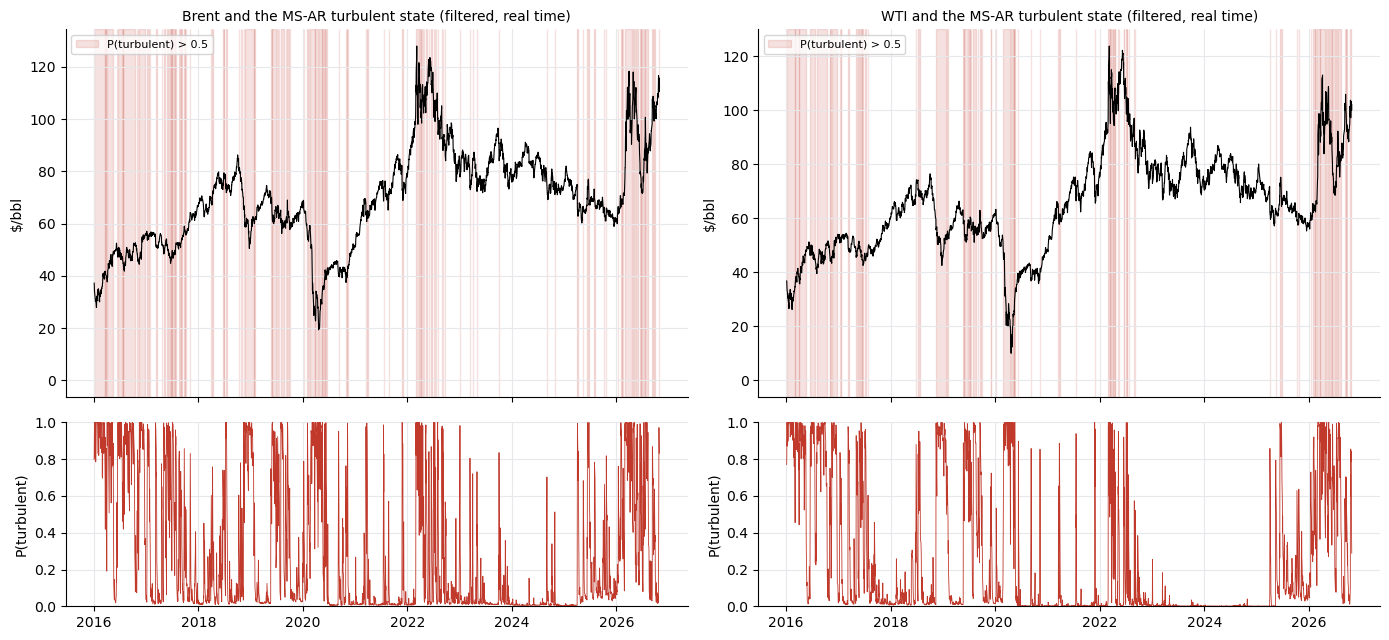

**Median estimated parameters over re-estimations**

vol_calm_ann_%  vol_turb_ann_%  p_stay_calm  p_stay_turb    phi  calm spell (days)  turbulent spell (days)
Brent MSAR           24.945          66.549        0.980        0.925 -0.000               50.0                    13.0
      MSARX          25.061          66.319        0.982        0.926 -0.085               56.0                    14.0
WTI   MSAR           28.411          70.369        0.990        0.955 -0.025              100.0                    22.0
      MSARX          28.420          69.813        0.990        0.952 -0.033              100.0                    21.0

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for j, t in enumerate(cfg.targets):
    pt = RES[(t, "MSAR")][1].dropna()
    px = prices[t].reindex(pt.index)
    axes[0, j].plot(px.index, px, color="black", lw=0.8)
    axes[0, j].fill_between(pt.index, 0, 1, where=(pt > 0.5).to_numpy(), color="#C0392B", alpha=0.15,
                            transform=axes[0, j].get_xaxis_transform(), label="P(turbulent) > 0.5")
    axes[0, j].set_title(f"{NAMES[t]} and the MS-AR turbulent state (filtered, real time)", fontsize=10)
    axes[0, j].set_ylabel("$/bbl"); axes[0, j].legend(fontsize=8, loc="upper left")
    axes[1, j].plot(pt.index, pt, color="#C0392B", lw=0.6); axes[1, j].set_ylim(0, 1); axes[1, j].set_ylabel("P(turbulent)")
fig.tight_layout(); fig.savefig(cfg.output_dir / "regimes.png", dpi=150); plt.show()
summ = pd.concat({(NAMES[t], m): RES[(t, m)][2][["vol_calm_ann_%", "vol_turb_ann_%", "p_stay_calm", "p_stay_turb", "phi"]].median()
                  for t in cfg.targets for m in MODELS}, axis=1).T.round(3)
summ["calm spell (days)"] = (1 / (1 - summ["p_stay_calm"])).round(0)
summ["turbulent spell (days)"] = (1 / (1 - summ["p_stay_turb"])).round(0)
display(Markdown("**Median estimated parameters over re-estimations**")); display(summ)

## 5. Results

### 5.1 Accuracy and direction

Price errors in \$/bbl. **RMSE ratio vs RW** below 1 means better than no change. DM p-value: one-sided
Diebold–Mariano test (HLN correction, Newey–West variance) that the model has lower squared price error than RW.
Direction: hit rate and precision / recall / F1 for "price goes up". Coverage: share of outcomes inside the 80% and 95% intervals.

In [7]:
def dm_pvalue(e_m, e_b, h):
    d = e_m ** 2 - e_b ** 2
    n = len(d)
    if n < 30 or np.allclose(d, 0):
        return np.nan
    u = d - d.mean()
    v = u @ u / n + 2 * sum((1 - k / h) * (u[k:] @ u[:-k]) / n for k in range(1, h))
    if v <= 0:
        return np.nan
    stat = d.mean() / np.sqrt(v / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stats.t.cdf(stat, n - 1)


ALL = ["RW", "HistMean", "AR", "MSAR_raw", "MSAR", "MSARX_raw", "MSARX"]


def evaluate(df):
    rows = []
    for (h, smp), g in df.dropna(subset=["y"]).groupby(["h", "sample"]):
        e_rw = g["P_t"] - g["P_target"]
        for m in ALL:
            e = g["P_t"] * np.exp(g[m]) - g["P_target"]
            row = {"sample": smp, "h": h, "model": m, "n": len(g), "MAE_$": e.abs().mean(),
                   "RMSE_$": np.sqrt((e ** 2).mean()), "MAPE_%": 100 * (e.abs() / g["P_target"]).mean(),
                   "RMSE_ratio_vs_RW": np.sqrt((e ** 2).mean() / (e_rw ** 2).mean()),
                   "MAE_ratio_vs_RW": e.abs().mean() / e_rw.abs().mean()}
            if m != "RW":
                row["DM_p"] = dm_pvalue(e.to_numpy(), e_rw.to_numpy(), h)
                up_hat, up = g[m] > 0, g["y"] > 0
                tp = (up_hat & up).sum()
                prec, rec = tp / max(up_hat.sum(), 1), tp / max(up.sum(), 1)
                row.update({"hit_%": 100 * (up_hat == up).mean(), "up_share_%": 100 * up.mean(),
                            "precision_up": prec, "recall_up": rec,
                            "F1_up": 2 * prec * rec / (prec + rec) if prec + rec > 0 else 0.0})
            if m in MODELS:
                res = g["y"] - g[m]
                row["cover80_%"] = 100 * ((res >= g[f"{m}_q10"]) & (res <= g[f"{m}_q90"])).mean()
                row["cover95_%"] = 100 * ((res >= g[f"{m}_q025"]) & (res <= g[f"{m}_q975"])).mean()
            rows.append(row)
    return pd.DataFrame(rows)


MET = {t: evaluate(FC[t][FC[t]["sample"].isin(["Out-of-sample", "Live test"])]) for t in cfg.targets}
for t in cfg.targets:
    MET[t].to_csv(cfg.output_dir / f"metrics_{NAMES[t].lower()}.csv", index=False)
    oos = MET[t][MET[t]["sample"] == "Out-of-sample"]
    display(Markdown(f"**{NAMES[t]}, out-of-sample: price RMSE ratio vs RW** (all models and benchmarks)"))
    display(oos.pivot(index="model", columns="h", values="RMSE_ratio_vs_RW").loc[ALL].round(3))
    display(Markdown(f"**{NAMES[t]}, out-of-sample: MAE ratio vs RW**"))
    display(oos.pivot(index="model", columns="h", values="MAE_ratio_vs_RW").loc[ALL].round(3))

**Brent, out-of-sample: price RMSE ratio vs RW** (all models and benchmarks)

h,1,5,10,20,30,40,50,60
model,,,,,,,,
RW,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
HistMean,1.000,1.002,1.006,1.012,1.018,1.021,1.024,1.026
AR,1.002,1.003,1.006,1.011,1.017,1.021,1.024,1.027
MSAR_raw,1.002,1.009,1.014,1.018,1.025,1.027,1.028,1.029
MSAR,1.001,1.003,1.005,1.007,1.011,1.012,1.012,1.013
MSARX_raw,0.999,1.006,1.011,1.017,1.024,1.026,1.028,1.030
MSARX,0.998,1.002,1.004,1.007,1.010,1.011,1.012,1.012


**Brent, out-of-sample: MAE ratio vs RW**

h,1,5,10,20,30,40,50,60
model,,,,,,,,
RW,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
HistMean,1.000,1.004,1.009,1.020,1.028,1.036,1.040,1.046
AR,1.001,1.005,1.010,1.019,1.027,1.034,1.039,1.045
MSAR_raw,1.004,1.008,1.018,1.026,1.040,1.044,1.050,1.052
MSAR,1.001,1.002,1.007,1.011,1.018,1.020,1.022,1.023
MSARX_raw,1.003,1.005,1.014,1.023,1.037,1.043,1.049,1.052
MSARX,1.000,1.002,1.005,1.010,1.017,1.019,1.021,1.023


**WTI, out-of-sample: price RMSE ratio vs RW** (all models and benchmarks)

h,1,5,10,20,30,40,50,60
model,,,,,,,,
RW,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
HistMean,1.001,1.003,1.006,1.012,1.017,1.021,1.024,1.027
AR,1.002,1.003,1.005,1.011,1.016,1.020,1.023,1.026
MSAR_raw,1.004,1.007,1.009,1.020,1.025,1.029,1.030,1.031
MSAR,1.002,1.003,1.003,1.008,1.011,1.012,1.013,1.013
MSARX_raw,1.005,1.007,1.008,1.019,1.024,1.027,1.028,1.029
MSARX,1.002,1.003,1.003,1.008,1.010,1.012,1.012,1.012


**WTI, out-of-sample: MAE ratio vs RW**

h,1,5,10,20,30,40,50,60
model,,,,,,,,
RW,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
HistMean,1.000,1.003,1.007,1.017,1.027,1.031,1.040,1.044
AR,1.003,1.003,1.007,1.016,1.026,1.028,1.036,1.041
MSAR_raw,1.003,1.003,1.012,1.025,1.037,1.039,1.050,1.053
MSAR,1.001,1.000,1.005,1.011,1.016,1.017,1.022,1.023
MSARX_raw,1.003,1.003,1.011,1.024,1.035,1.037,1.047,1.050
MSARX,1.001,1.001,1.004,1.010,1.015,1.016,1.020,1.022


In [8]:
cols = ["h", "n", "MAE_$", "RMSE_$", "MAPE_%", "RMSE_ratio_vs_RW", "DM_p", "hit_%", "up_share_%", "precision_up",
        "recall_up", "F1_up", "cover80_%", "cover95_%"]
for t in cfg.targets:
    oos = MET[t][MET[t]["sample"] == "Out-of-sample"]
    for m in MODELS:
        display(Markdown(f"**{NAMES[t]}, out-of-sample, {m} in detail**"))
        display(oos[oos["model"] == m][cols].round(3).set_index("h"))

**Brent, out-of-sample, MSAR in detail**

,n,MAE_$,RMSE_$,MAPE_%,RMSE_ratio_vs_RW,DM_p,hit_%,up_share_%,precision_up,recall_up,F1_up,cover80_%,cover95_%
h,,,,,,,,,,,,,
1,2699,1.194,1.823,1.747,1.001,0.673,50.945,53.872,0.544,0.558,0.551,79.326,93.738
5,2695,2.710,3.922,4.043,1.003,0.800,48.349,54.471,0.526,0.514,0.520,78.998,93.432
10,2690,3.800,5.361,5.753,1.005,0.958,46.506,56.022,0.524,0.489,0.506,78.401,93.866
20,2680,5.311,7.428,8.023,1.007,0.980,44.254,57.239,0.515,0.448,0.479,81.418,95.373
30,2670,6.547,9.049,10.041,1.011,0.995,41.311,56.105,0.473,0.409,0.439,80.449,94.082
40,2660,7.632,10.555,11.888,1.012,0.992,41.278,55.677,0.469,0.408,0.436,80.865,93.083
50,2650,8.581,11.832,13.405,1.012,0.983,41.887,53.811,0.456,0.416,0.435,79.245,92.151
60,2640,9.287,12.862,14.529,1.013,0.966,42.083,54.129,0.462,0.425,0.443,78.712,91.742


**Brent, out-of-sample, MSARX in detail**

,n,MAE_$,RMSE_$,MAPE_%,RMSE_ratio_vs_RW,DM_p,hit_%,up_share_%,precision_up,recall_up,F1_up,cover80_%,cover95_%
h,,,,,,,,,,,,,
1,2699,1.193,1.819,1.745,0.998,0.188,51.167,53.872,0.547,0.543,0.545,79.363,93.701
5,2695,2.707,3.919,4.038,1.002,0.740,48.831,54.471,0.530,0.529,0.530,75.510,91.725
10,2690,3.794,5.355,5.743,1.004,0.924,47.732,56.022,0.535,0.518,0.526,75.502,92.007
20,2680,5.303,7.422,8.011,1.007,0.963,44.179,57.239,0.514,0.465,0.488,77.873,93.993
30,2670,6.539,9.043,10.029,1.010,0.986,41.723,56.105,0.478,0.430,0.453,76.929,92.959
40,2660,7.626,10.550,11.877,1.011,0.982,41.805,55.677,0.475,0.432,0.453,77.068,91.729
50,2650,8.575,11.828,13.397,1.012,0.966,41.811,53.811,0.458,0.441,0.449,76.453,90.755
60,2640,9.285,12.859,14.526,1.012,0.944,41.856,54.129,0.462,0.446,0.454,75.947,90.265


**WTI, out-of-sample, MSAR in detail**

,n,MAE_$,RMSE_$,MAPE_%,RMSE_ratio_vs_RW,DM_p,hit_%,up_share_%,precision_up,recall_up,F1_up,cover80_%,cover95_%
h,,,,,,,,,,,,,
1,2699,1.204,1.801,1.936,1.002,0.930,50.871,53.724,0.537,0.628,0.579,79.474,93.405
5,2695,2.701,3.886,4.348,1.003,0.820,50.612,54.100,0.540,0.595,0.566,78.442,94.063
10,2690,3.757,5.271,6.178,1.003,0.866,48.550,56.245,0.541,0.565,0.553,79.257,93.978
20,2680,5.342,7.344,8.823,1.008,0.985,44.478,55.410,0.499,0.514,0.507,81.455,94.813
30,2670,6.525,8.995,11.038,1.011,0.990,41.610,56.330,0.482,0.480,0.481,82.584,94.307
40,2660,7.593,10.465,13.102,1.012,0.986,42.594,56.203,0.489,0.484,0.487,82.895,93.045
50,2650,8.447,11.688,14.634,1.013,0.969,40.642,54.906,0.459,0.459,0.459,81.208,92.415
60,2640,9.108,12.661,15.777,1.013,0.939,41.515,53.220,0.452,0.465,0.458,81.932,92.159


**WTI, out-of-sample, MSARX in detail**

,n,MAE_$,RMSE_$,MAPE_%,RMSE_ratio_vs_RW,DM_p,hit_%,up_share_%,precision_up,recall_up,F1_up,cover80_%,cover95_%
h,,,,,,,,,,,,,
1,2699,1.204,1.802,1.936,1.002,0.979,50.389,53.724,0.535,0.588,0.560,79.585,93.368
5,2695,2.701,3.887,4.349,1.003,0.866,49.573,54.100,0.532,0.570,0.550,78.108,94.026
10,2690,3.755,5.271,6.175,1.003,0.859,47.249,56.245,0.531,0.533,0.532,79.071,94.089
20,2680,5.341,7.342,8.820,1.008,0.977,44.030,55.410,0.495,0.488,0.491,81.567,95.000
30,2670,6.519,8.991,11.027,1.010,0.978,41.948,56.330,0.484,0.463,0.474,82.360,94.457
40,2660,7.584,10.457,13.088,1.012,0.968,42.368,56.203,0.487,0.469,0.478,82.556,93.083
50,2650,8.432,11.674,14.612,1.012,0.937,40.642,54.906,0.459,0.449,0.454,81.057,92.491
60,2640,9.092,12.644,15.753,1.012,0.896,41.667,53.220,0.452,0.456,0.454,82.045,92.273


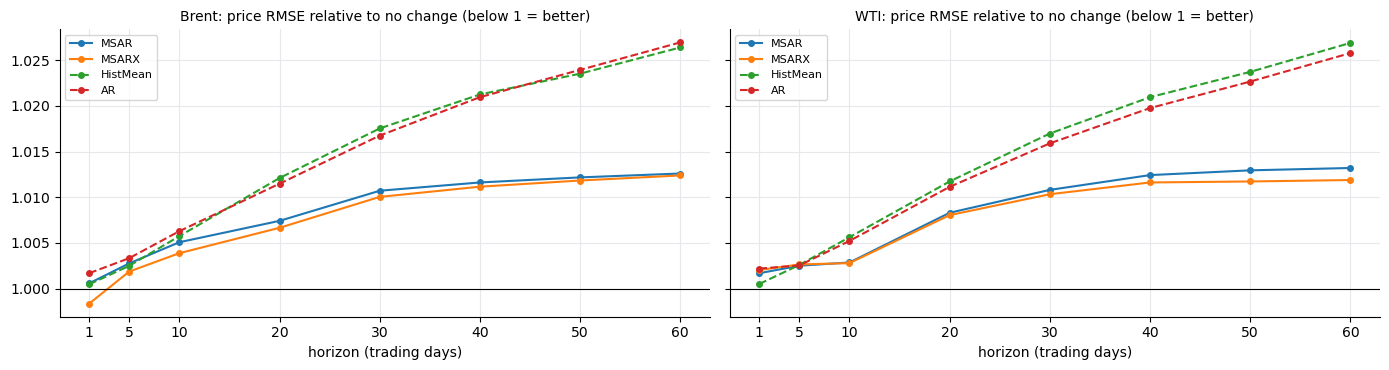

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, t in zip(axes, cfg.targets):
    oos = MET[t][MET[t]["sample"] == "Out-of-sample"].pivot(index="h", columns="model", values="RMSE_ratio_vs_RW")
    for m, st in (("MSAR", "-"), ("MSARX", "-"), ("HistMean", "--"), ("AR", "--")):
        ax.plot(oos.index, oos[m], ls=st, marker="o", ms=4, label=m)
    ax.axhline(1, color="black", lw=0.8); ax.set_xticks(list(cfg.horizons))
    ax.set_title(f"{NAMES[t]}: price RMSE relative to no change (below 1 = better)", fontsize=10)
    ax.set_xlabel("horizon (trading days)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(cfg.output_dir / "rmse_ratio_by_horizon.png", dpi=150); plt.show()

### 5.2 Robustness

Out-of-sample price RMSE ratio vs RW by volatility regime at the forecast origin and by year.
High volatility: 60-day realized volatility above the median of all its earlier values (known at the origin).
The by-year table is the stability check across out-of-sample windows.

In [10]:
def ratio_by(df, key, m):
    f = lambda g: np.sqrt(((g["P_t"] * np.exp(g[m]) - g["P_target"]) ** 2).mean() / ((g["P_t"] - g["P_target"]) ** 2).mean())
    return df.groupby([key, "h"])[["P_t", m, "P_target"]].apply(f).unstack("h").round(3)


for t in cfg.targets:
    o = FC[t][FC[t]["sample"] == "Out-of-sample"].dropna(subset=["y"]).copy()
    rv60 = RET[t].rolling(60, min_periods=45).std()
    vol_reg = pd.Series(np.where(rv60 > rv60.expanding(250).median().shift(1), "high volatility", "low volatility"),
                        index=rv60.index).where(rv60.notna())
    o["vol regime"], o["year"] = o["origin"].map(vol_reg), o["origin"].dt.year
    for m in MODELS:
        rr, ry = ratio_by(o, "vol regime", m), ratio_by(o, "year", m)
        rr.to_csv(cfg.output_dir / f"robust_regime_{NAMES[t].lower()}_{m}.csv")
        ry.to_csv(cfg.output_dir / f"robust_year_{NAMES[t].lower()}_{m}.csv")
        display(Markdown(f"**{NAMES[t]} · {m}: by volatility regime**")); display(rr)
        display(Markdown(f"**{NAMES[t]} · {m}: by year**")); display(ry)

**Brent · MSAR: by volatility regime**

h,1,5,10,20,30,40,50,60
vol regime,,,,,,,,
high volatility,1.001,1.003,1.004,1.007,1.011,1.015,1.019,1.022
low volatility,1.001,1.003,1.008,1.009,1.010,1.007,1.004,1.002


**Brent · MSAR: by year**

h,1,5,10,20,30,40,50,60
year,,,,,,,,
2016,1.001,1.012,1.024,1.041,1.067,1.082,1.086,1.090
2017,1.000,1.002,1.007,1.018,1.031,1.040,1.049,1.060
2018,0.996,1.000,1.000,1.002,1.005,1.007,1.010,1.012
2019,0.998,0.999,1.001,1.010,1.016,1.015,1.013,1.009
2020,1.003,1.003,1.004,1.006,1.008,1.009,1.010,1.013
2021,1.002,1.004,0.994,0.990,0.988,0.979,0.974,0.968
2022,1.002,1.002,1.005,1.009,1.018,1.024,1.040,1.050
2023,1.000,1.011,1.017,1.011,1.012,1.013,1.014,1.017
2024,1.002,1.004,1.006,1.009,1.013,1.017,1.026,1.040


**Brent · MSARX: by volatility regime**

h,1,5,10,20,30,40,50,60
vol regime,,,,,,,,
high volatility,0.999,1.002,1.002,1.005,1.009,1.013,1.018,1.021
low volatility,0.997,1.002,1.008,1.009,1.011,1.008,1.005,1.003


... (6 outputs left out)

**WTI · MSARX: by volatility regime**

h,1,5,10,20,30,40,50,60
vol regime,,,,,,,,
high volatility,1.002,1.003,1.002,1.008,1.011,1.016,1.020,1.025
low volatility,1.003,1.003,1.005,1.008,1.009,1.007,1.003,0.999


**WTI · MSARX: by year**

h,1,5,10,20,30,40,50,60
year,,,,,,,,
2016,1.001,1.008,1.015,1.030,1.051,1.064,1.066,1.069
2017,1.000,1.000,1.000,1.000,1.006,1.014,1.021,1.031
2018,0.998,1.000,0.999,0.999,0.998,0.998,0.997,0.996
2019,0.999,1.002,1.007,1.017,1.022,1.023,1.026,1.019
2020,1.002,1.004,1.007,1.010,1.011,1.012,1.013,1.015
2021,1.001,1.000,0.995,0.989,0.984,0.972,0.964,0.954
2022,1.005,1.004,1.001,1.009,1.018,1.028,1.047,1.061
2023,1.002,1.002,1.004,1.008,1.012,1.014,1.015,1.014
2024,1.001,1.002,1.002,1.005,1.009,1.015,1.024,1.039


### 5.3 Economic value

Same rule as the XGBoost notebook. $H$ = holding period = forecast horizon used; $H=20$ is the main rule.
Each day: long if the $H$-day forecast is positive, short if negative, size $\min(2,\ 25\%/\sigma^{ann}_t)$
(20-day realized volatility), no position if $|\hat y_{t,H}|\le 0.1\,\sigma_{t,H}$. Overlapping tranches: $1/H$ of capital
opened daily and held $H$ days. Costs 5 bp per unit of change in the position.
Benchmarks: buy and hold, and a vol-targeted long position. The last column rescales each strategy to 10% annual
volatility (return × 10% / its volatility), which compares returns per unit of risk.

annual return %  annual vol %  Sharpe  max drawdown %  days with a position %  turnover per year  total costs %  return at 10% vol %
target strategy                                                                                                                                               
Brent  MSAR, H = 5                  -0.23          5.98   -0.04          -15.97                   11.25               3.17           1.71                -0.39
       MSAR, H = 10                 -2.35          7.76   -0.30          -30.59                   22.35               2.94           1.59                -3.03
       MSAR, H = 20                 -3.85         10.68   -0.36          -42.05                   43.82               2.82           1.52                -3.61
       MSARX, H = 5                 -0.43          6.82   -0.06          -18.32                   14.30               4.46           2.41                -0.63
       MSARX, H = 10                -2.34          8.85   -0.26          -33.18                   24.04               3.40           1.83                -2.64
       MSARX, H = 20                -3.31         11.77   -0.28          -41.25                   43.79               3.04           1.64                -2.81
       Long vol-targeted             5.20         28.36    0.18          -53.68                  100.00               9.22           4.98                 1.83
       Buy and hold                 10.21         41.77    0.24          -77.60                  100.00               0.09           0.05                 2.45
WTI    MSAR, H = 5                   0.61          5.84    0.10          -17.01                    7.87               1.70           0.92                 1.04
       MSAR, H = 10                 -0.27          6.19   -0.04          -20.12                   12.57               1.17           0.63                -0.44
       MSAR, H = 20                 -1.81          7.31   -0.25          -27.45                   27.06               1.27           0.69                -2.47
       MSARX, H = 5                 -0.43          6.03   -0.07          -17.61                    7.98               2.08           1.12                -0.71
       MSARX, H = 10                -0.43          6.69   -0.06          -20.65                   11.65               1.44           0.78                -0.64
       MSARX, H = 20                -1.12          8.58   -0.13          -31.62                   24.78               1.51           0.81                -1.31
       Long vol-targeted             2.72         28.11    0.10          -61.46                  100.00               8.22           4.44                 0.97
       Buy and hold                  9.21         49.94    0.18          -86.90                  100.00               0.09           0.05                 1.84

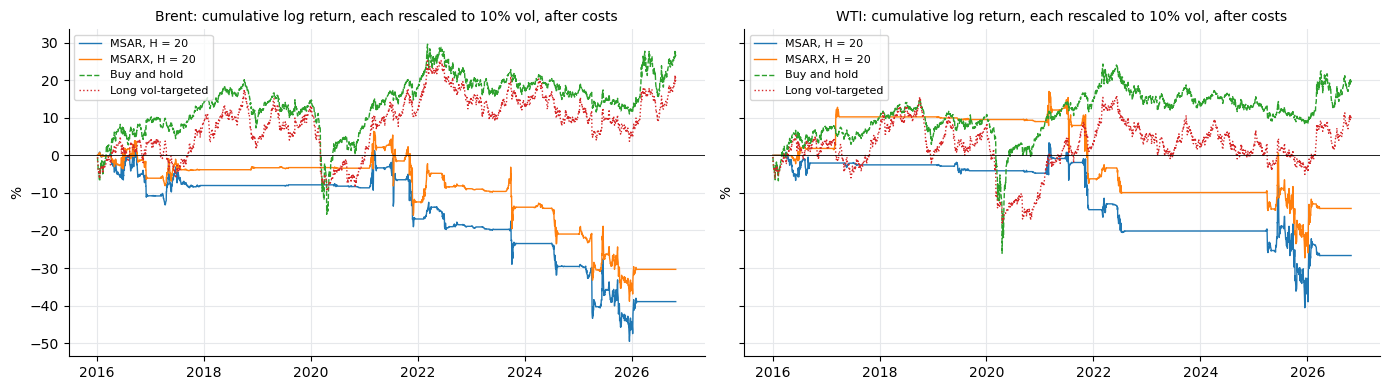

In [11]:
def tranche(w, H):
    return w.fillna(0.0).rolling(H, min_periods=1).sum() / H


def run_rule(pos, ret):
    pos = pos.reindex(ret.index).fillna(0.0)
    turn = pos.diff().abs().fillna(pos.abs())
    return pos * ret - cfg.cost_bps / 1e4 * turn, pos, turn


def perf(pnl, pos, turn):
    cum = pnl.cumsum()
    vol = np.sqrt(252) * pnl.std()
    return {"annual return %": 100 * 252 * pnl.mean(), "annual vol %": 100 * vol,
            "Sharpe": 252 * pnl.mean() / vol if vol > 0 else np.nan,
            "max drawdown %": 100 * (np.exp((cum - cum.cummax()).min()) - 1),
            "days with a position %": 100 * (pos.abs() > 1e-9).mean(), "turnover per year": 252 * turn.mean(),
            "total costs %": 100 * cfg.cost_bps / 1e4 * turn.sum(),
            f"return at {cfg.compare_vol:.0f}% vol %": cfg.compare_vol * 252 * pnl.mean() / vol if vol > 0 else np.nan}


rows_e, pnls = [], {}
for t in cfg.targets:
    fc = FC[t]
    ret = fc[(fc["h"] == 1) & fc["sample"].isin(["Out-of-sample", "Live test"])].dropna(subset=["y"]).set_index("origin")["y"]
    rv = (RET[t].rolling(20, min_periods=15).std() * np.sqrt(252) / 100).reindex(ret.index)
    size = np.minimum(cfg.max_leverage, cfg.target_vol / (100 * rv))
    for m in MODELS:
        for H in cfg.trade_hs:
            f = fc[fc["h"] == H].drop_duplicates("origin").set_index("origin")[m].reindex(ret.index)
            w = np.sign(f) * size * (f.abs() > cfg.noise_k * rv * np.sqrt(H / 252))
            pnl, pos, turn = run_rule(tranche(w, H), ret)
            rows_e.append({"target": NAMES[t], "strategy": f"{m}, H = {H}", **perf(pnl, pos, turn)})
            pnls[(t, f"{m}, H = {H}")] = pnl
    for name, pos in (("Long vol-targeted", size), ("Buy and hold", pd.Series(1.0, index=ret.index))):
        pnl, pos_, turn = run_rule(pos, ret)
        rows_e.append({"target": NAMES[t], "strategy": name, **perf(pnl, pos_, turn)})
        pnls[(t, name)] = pnl
econ = pd.DataFrame(rows_e).set_index(["target", "strategy"]).round(2)
econ.to_csv(cfg.output_dir / "economic_value.csv")
display(econ)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, t in zip(axes, cfg.targets):
    for name, ls in ((f"MSAR, H = {cfg.main_trade_h}", "-"), (f"MSARX, H = {cfg.main_trade_h}", "-"),
                     ("Buy and hold", "--"), ("Long vol-targeted", ":")):
        pnl = pnls[(t, name)]
        sd = np.sqrt(252) * pnl.std()
        if sd > 0:
            ax.plot(pnl.index, 100 * (pnl * cfg.compare_vol / 100 / sd).cumsum(), ls=ls, lw=1.0, label=name)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{NAMES[t]}: cumulative log return, each rescaled to {cfg.compare_vol:.0f}% vol, after costs", fontsize=10)
    ax.set_ylabel("%"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(cfg.output_dir / "equity_curves.png", dpi=150); plt.show()

## 6. Latest forecast

The last re-estimated models, filtered to the latest close, forecast 1 to 60 days ahead (shrunk point forecast and
80% / 95% simulated intervals).

In [12]:
rows_l = []
rng = np.random.default_rng(cfg.seed + 1)
for t in cfg.targets:
    r = RET[t].to_numpy()
    N = len(r)
    for m in MODELS:
        mod, params, par, Xs, scaler = RES[(t, m)][3]
        lo = N - cfg.window
        fmod = MarkovAutoregression(np.nan_to_num(r[lo:N]), k_regimes=2, order=1,
                                    exog=None if Xs is None else Xs[lo:N], switching_ar=False,
                                    switching_variance=True, switching_exog=False)
        filt = np.asarray(fmod.filter(params).filtered_marginal_probabilities)[:, par["order"]][[-1]]
        xb = Xs[[N - 1]] @ par["beta"] if Xs is not None else np.zeros(1)
        xnext = (stdz(EXOG_RAW[t].shift(-1).to_numpy()[[N - 1]], *scaler) @ par["beta"]) if Xs is not None else np.zeros(1)
        if Xs is not None:                                   # tomorrow's input = today's raw values, known now
            today = pd.DataFrame({EXOG_RAW[t].columns[0]: [RET["wti_fut" if t == "brent_fut" else "brent_fut"].iloc[-1]],
                                  "dxy_ret": [100 * np.log(dxy).diff().iloc[-1]],
                                  "spread_usd": [prices["brent_fut"].iloc[-1] - prices["wti_fut"].iloc[-1]]}).to_numpy()
            xnext = stdz(today, *scaler) @ par["beta"]
        cum_mean, sims = forecast_block(r[[N - 1]], xb, filt, par, max(cfg.horizons), 20000, rng, xnext)
        P0 = prices[t].iloc[-1]
        for h in cfg.horizons:
            mu = cfg.shrink * cum_mean[0, h - 1] / 100
            q = np.quantile(sims[0, :, h - 1] / 100 - mu, [0.025, 0.10, 0.90, 0.975])
            rows_l.append({"target": NAMES[t], "model": m, "asof": prices.index[-1].date(), "h": h,
                           "price_now": P0, "forecast_price": P0 * np.exp(mu), "lo95": P0 * np.exp(mu + q[0]),
                           "lo80": P0 * np.exp(mu + q[1]), "hi80": P0 * np.exp(mu + q[2]), "hi95": P0 * np.exp(mu + q[3]),
                           "P(turbulent)": filt[0, 1]})
live = pd.DataFrame(rows_l)
live.to_csv(cfg.output_dir / "live_forecast.csv", index=False)
log_path = cfg.output_dir / "forecast_log.csv"
flog = pd.concat([pd.read_csv(log_path), live]) if log_path.exists() else live
flog.astype({"asof": str}).drop_duplicates(["target", "model", "asof", "h"], keep="last").to_csv(log_path, index=False)
display(live.set_index(["target", "model", "h"]).drop(columns=["asof"]).round(2))

price_now  forecast_price    lo95    lo80    hi80    hi95  P(turbulent)
target model h                                                                          
Brent  MSAR  1      110.82          110.73  102.22  105.40  116.06  119.61          0.83
             5      110.82          110.51   92.96   99.27  121.91  129.65          0.83
             10     110.82          110.35   87.04   95.68  125.42  136.78          0.83
             20     110.82          110.25   80.09   91.55  130.53  145.55          0.83
             30     110.82          110.27   76.63   88.86  134.43  151.95          0.83
             40     110.82          110.35   73.60   86.75  138.35  157.42          0.83
             50     110.82          110.44   71.33   84.94  141.13  162.09          0.83
             60     110.82          110.55   69.54   83.46  144.28  168.00          0.83
       MSARX 1      110.82          110.94  102.91  105.99  116.35  119.88          0.79
             5      110.82          110.79   94.90  100.89  121.21  128.66          0.79
             10     110.82          110.70   89.43   97.58  124.54  134.76          0.79
             20     110.82          110.65   83.67   93.59  129.19  142.84          0.79
             30     110.82          110.70   79.76   91.42  132.78  148.61          0.79
             40     110.82          110.79   77.26   89.54  135.67  153.61          0.79
             50     110.82          110.89   75.23   87.75  138.76  158.12          0.79
             60     110.82          111.00   73.03   86.50  141.46  164.38          0.79
WTI    MSAR  1      102.08          102.10   96.09   98.84  105.56  108.49          0.29
             5      102.08          102.11   88.77   94.66  109.91  116.60          0.29
             10     102.08          102.13   84.01   91.96  113.42  123.48          0.29
             20     102.08          102.17   77.69   87.92  118.39  131.52          0.29
             30     102.08          102.22   73.43   85.28  122.84  138.71          0.29
             40     102.08          102.28   70.30   82.82  126.50  144.92          0.29
             50     102.08          102.35   68.09   80.94  129.95  151.31          0.29
             60     102.08          102.41   65.47   79.41  132.35  157.25          0.29
       MSARX 1      102.08          102.19   96.42   99.08  105.68  108.50          0.28
             5      102.08          102.20   89.39   95.07  110.20  117.00          0.28
             10     102.08          102.21   84.21   92.09  113.74  123.11          0.28
             20     102.08          102.25   77.56   87.97  119.01  131.91          0.28
             30     102.08          102.30   73.78   85.45  123.06  139.54          0.28
             40     102.08          102.36   69.87   82.84  126.86  146.33          0.28
             50     102.08          102.42   66.96   80.77  130.27  151.51          0.28
             60     102.08          102.49   64.65   78.89  133.43  157.54          0.28

## 7. Takeaways

In [13]:
lines = []
for t in cfg.targets:
    oos = MET[t][MET[t]["sample"] == "Out-of-sample"].set_index(["model", "h"])
    for m in MODELS:
        o = oos.loc[m]
        sig = list(o.index[o["DM_p"] < 0.05])
        lines.append(f"**{NAMES[t]} · {m}**: RMSE ratio vs RW {o['RMSE_ratio_vs_RW'].min():.3f} to {o['RMSE_ratio_vs_RW'].max():.3f}, "
                     f"lower than RW at {int((o['RMSE_ratio_vs_RW'] < 1).sum())} of {len(o)} horizons; "
                     + (f"significant at 5% (DM) at h = {sig}. " if sig else "none significant at 5% (DM). ")
                     + f"Hit rate {o['hit_%'].min():.0f}–{o['hit_%'].max():.0f}%. "
                     f"80% / 95% coverage {o['cover80_%'].min():.0f}–{o['cover80_%'].max():.0f}% / "
                     f"{o['cover95_%'].min():.0f}–{o['cover95_%'].max():.0f}%. "
                     f"Sharpe at H = {cfg.main_trade_h}: {econ.loc[(NAMES[t], f'{m}, H = {cfg.main_trade_h}'), 'Sharpe']:.2f} "
                     f"(buy and hold {econ.loc[(NAMES[t], 'Buy and hold'), 'Sharpe']:.2f}).")
display(Markdown("\n".join("- " + s for s in lines)))

- **Brent · MSAR**: RMSE ratio vs RW 1.001 to 1.013, lower than RW at 0 of 8 horizons; none significant at 5% (DM). Hit rate 41–51%. 80% / 95% coverage 78–81% / 92–95%. Sharpe at H = 20: -0.36 (buy and hold 0.24).
- **Brent · MSARX**: RMSE ratio vs RW 0.998 to 1.012, lower than RW at 1 of 8 horizons; none significant at 5% (DM). Hit rate 42–51%. 80% / 95% coverage 76–79% / 90–94%. Sharpe at H = 20: -0.28 (buy and hold 0.24).
- **WTI · MSAR**: RMSE ratio vs RW 1.002 to 1.013, lower than RW at 0 of 8 horizons; none significant at 5% (DM). Hit rate 41–51%. 80% / 95% coverage 78–83% / 92–95%. Sharpe at H = 20: -0.25 (buy and hold 0.18).
- **WTI · MSARX**: RMSE ratio vs RW 1.002 to 1.012, lower than RW at 0 of 8 horizons; none significant at 5% (DM). Hit rate 41–50%. 80% / 95% coverage 78–83% / 92–95%. Sharpe at H = 20: -0.13 (buy and hold 0.18).